In [1]:
import os
import glob

import numpy as np
import pandas as pd
import scipy.io

from scipy.stats import kurtosis, skew

from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt


In [2]:
dataset_path = r"./CWRU-dataset"

In [3]:
# Recursively list all .mat files
search_path = os.path.join(dataset_path, "**", "*.mat")
all_mat_files = glob.glob(search_path, recursive=True)

print(f"Total .mat files found: {len(all_mat_files)}")
for f in all_mat_files[:10]:  # show first 10 as a sample
    print(f)


Total .mat files found: 161
./CWRU-dataset\12k_Drive_End_Bearing_Fault_Data\B\007\118_0.mat
./CWRU-dataset\12k_Drive_End_Bearing_Fault_Data\B\007\119_1.mat
./CWRU-dataset\12k_Drive_End_Bearing_Fault_Data\B\007\120_2.mat
./CWRU-dataset\12k_Drive_End_Bearing_Fault_Data\B\007\121_3.mat
./CWRU-dataset\12k_Drive_End_Bearing_Fault_Data\B\014\185_0.mat
./CWRU-dataset\12k_Drive_End_Bearing_Fault_Data\B\014\186_1.mat
./CWRU-dataset\12k_Drive_End_Bearing_Fault_Data\B\014\187_2.mat
./CWRU-dataset\12k_Drive_End_Bearing_Fault_Data\B\014\188_3.mat
./CWRU-dataset\12k_Drive_End_Bearing_Fault_Data\B\021\222_0.mat
./CWRU-dataset\12k_Drive_End_Bearing_Fault_Data\B\021\223_1.mat


In [4]:
# Try to pick one example "Normal" file automatically
normal_files = [f for f in all_mat_files if "Normal" in f]

print(f"Normal files found: {len(normal_files)}")
if normal_files:
    example_normal_file = normal_files[0]
    print("Example normal file:", example_normal_file)
else:
    example_normal_file = None
    print("No normal files found with 'Normal' in the path. Check your folder names.")

Normal files found: 4
Example normal file: ./CWRU-dataset\Normal\100_Normal_3.mat


In [5]:
if example_normal_file is not None:
    mat_data = scipy.io.loadmat(example_normal_file)
    print("Keys in .mat file:")
    for k in mat_data.keys():
        print(k, "->", type(mat_data[k]), getattr(mat_data[k], "shape", ""))
else:
    print("No example file to inspect. Set example_normal_file manually.")


Keys in .mat file:
__header__ -> <class 'bytes'> 
__version__ -> <class 'str'> 
__globals__ -> <class 'list'> 
X100_DE_time -> <class 'numpy.ndarray'> (485643, 1)
X100_FE_time -> <class 'numpy.ndarray'> (485643, 1)
X100RPM -> <class 'numpy.ndarray'> (1, 1)


In [6]:
# Find the key that ends with 'DE_time'
de_key = None
for k in mat_data.keys():
    if k.endswith("DE_time"):
        de_key = k
        break

print("DE key found:", de_key)

if de_key is not None:
    signal = mat_data[de_key].flatten()
    print("Signal shape:", signal.shape)
    print("First 10 samples:", signal[:10])
else:
    signal = None
    print("No DE_time key found in this file.")


DE key found: X100_DE_time
Signal shape: (485643,)
First 10 samples: [0.01460308 0.05444862 0.10764554 0.13372246 0.11265231 0.08240308
 0.08699262 0.11056615 0.12767262 0.11348677]


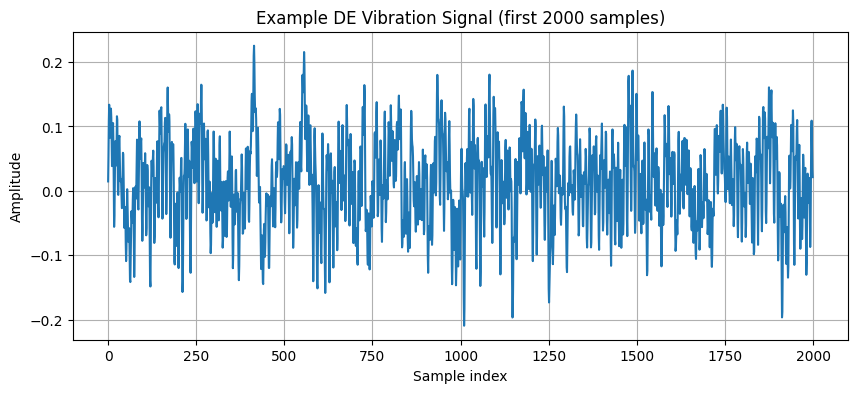

In [7]:
if signal is not None:
    plt.figure(figsize=(10, 4))
    plt.plot(signal[:2000])  # plot first 2000 samples
    plt.title("Example DE Vibration Signal (first 2000 samples)")
    plt.xlabel("Sample index")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()


In [10]:
def extract_features(signal, window_size=1024):
    """
    Splits the signal into windows and extracts statistical features.
    Each window gives:
        - mean
        - std
        - rms
        - peak
        - peak-to-peak
        - kurtosis
        - skewness
        - crest factor
    """
    num_windows = len(signal) // window_size
    features = []

    for i in range(num_windows):
        window = signal[i*window_size : (i+1)*window_size]

        mean_val = np.mean(window)
        std_val = np.std(window)
        rms_val = np.sqrt(np.mean(window**2))
        peak_val = np.max(np.abs(window))
        p2p_val = np.ptp(window)
        kurt_val = kurtosis(window)
        skew_val = skew(window)
        crest_factor = peak_val / rms_val if rms_val != 0 else 0

        features.append([
            mean_val, std_val, rms_val, peak_val,
            p2p_val, kurt_val, skew_val, crest_factor
        ])

    return np.array(features)




In [13]:
# Test feature extraction on the example DE signal
if signal is not None:
    feats = extract_features(signal, window_size=1024)
    print("Feature matrix shape:", feats.shape)

    df_feats = pd.DataFrame(feats, columns=[
        "mean", "std", "rms", "peak", "p2p",
        "kurtosis", "skewness", "crest_factor"
    ])
    df_feats.head()
else:
    print("No signal loaded.")

Feature matrix shape: (474, 8)


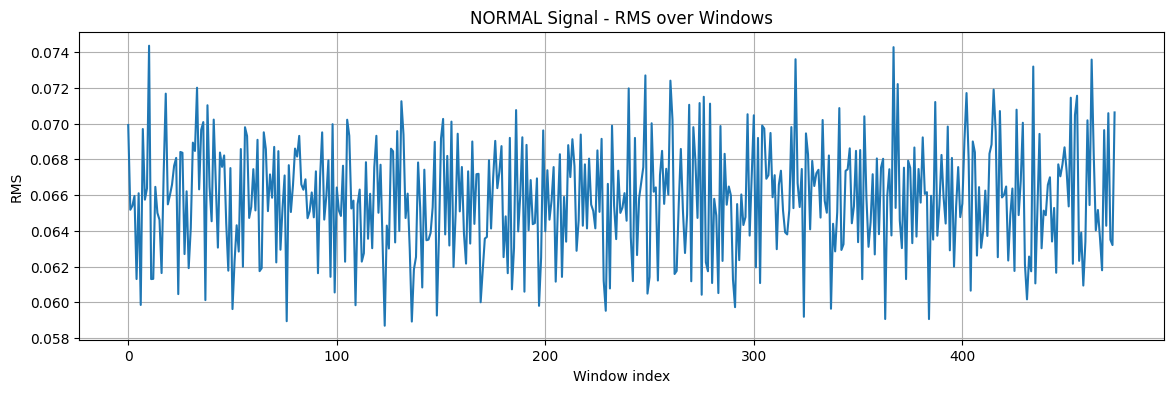

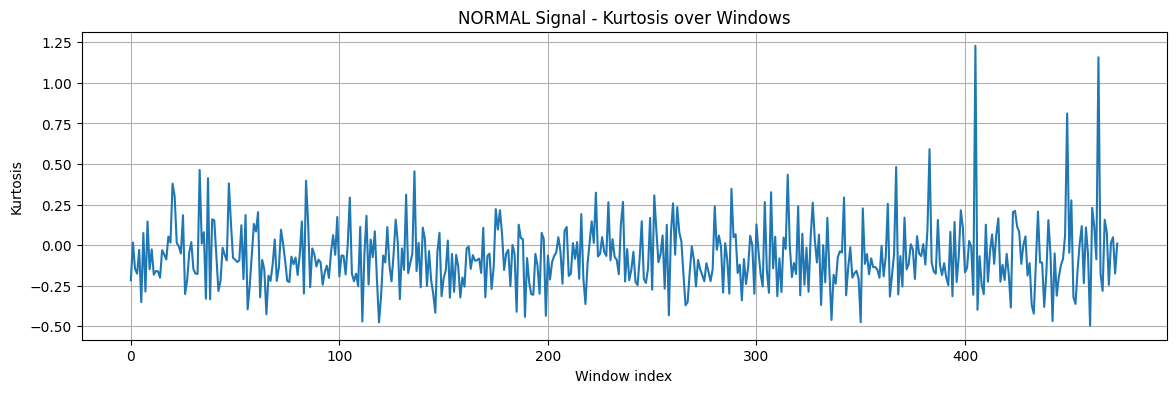

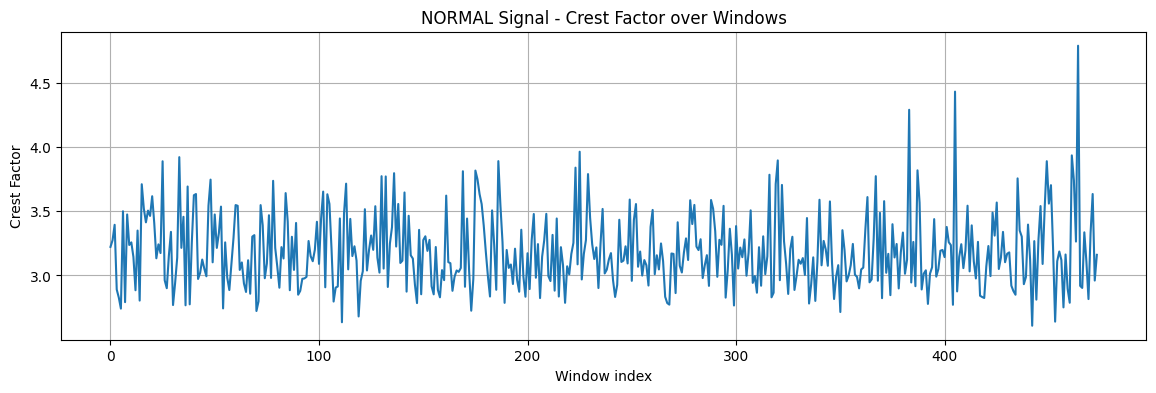

In [14]:
# Visualizing the extracted features for the NORMAL signal

feature_names = ["mean", "std", "rms", "peak", "p2p", "kurtosis", "skewness", "crest_factor"]

df_feats = pd.DataFrame(feats, columns=feature_names)

plt.figure(figsize=(14, 4))
plt.plot(df_feats["rms"])
plt.title("NORMAL Signal - RMS over Windows")
plt.xlabel("Window index")
plt.ylabel("RMS")
plt.grid(True)
plt.show()

plt.figure(figsize=(14, 4))
plt.plot(df_feats["kurtosis"])
plt.title("NORMAL Signal - Kurtosis over Windows")
plt.xlabel("Window index")
plt.ylabel("Kurtosis")
plt.grid(True)
plt.show()

plt.figure(figsize=(14, 4))
plt.plot(df_feats["crest_factor"])
plt.title("NORMAL Signal - Crest Factor over Windows")
plt.xlabel("Window index")
plt.ylabel("Crest Factor")
plt.grid(True)
plt.show()


# Faulty File


In [15]:
# Find one FAULT file (anything with 'Fault' in the path)
fault_files = [f for f in all_mat_files if "Fault" in f]

print("Fault files found:", len(fault_files))

if len(fault_files) > 0:
    example_fault_file = fault_files[0]
    print("Using fault file:", example_fault_file)

    fault_data = scipy.io.loadmat(example_fault_file)

    # find DE key
    fault_de_key = None
    for k in fault_data.keys():
        if k.endswith("DE_time"):
            fault_de_key = k
            break

    print("Fault DE key:", fault_de_key)

    if fault_de_key is not None:
        fault_signal = fault_data[fault_de_key].flatten()
        print("Fault signal length:", len(fault_signal))
else:
    print("No fault files found.")


Fault files found: 157
Using fault file: ./CWRU-dataset\12k_Drive_End_Bearing_Fault_Data\B\007\118_0.mat
Fault DE key: X118_DE_time
Fault signal length: 122571


In [16]:
if fault_de_key is not None:
    fault_feats = extract_features(fault_signal, window_size=1024)

    df_fault_feats = pd.DataFrame(fault_feats, columns=feature_names)
    df_fault_feats.head()


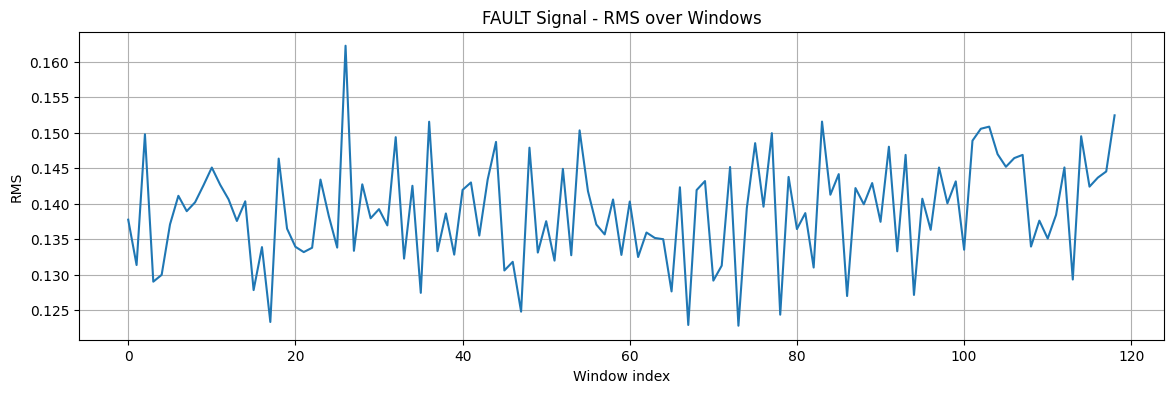

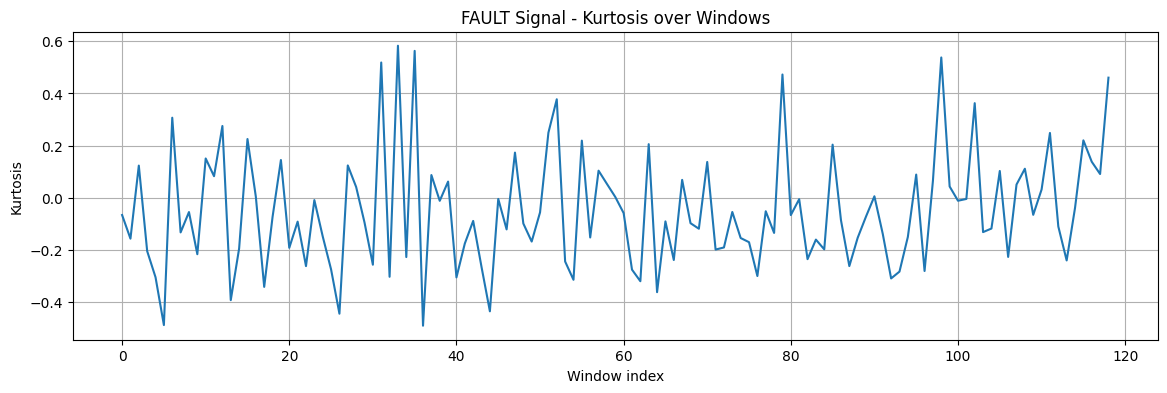

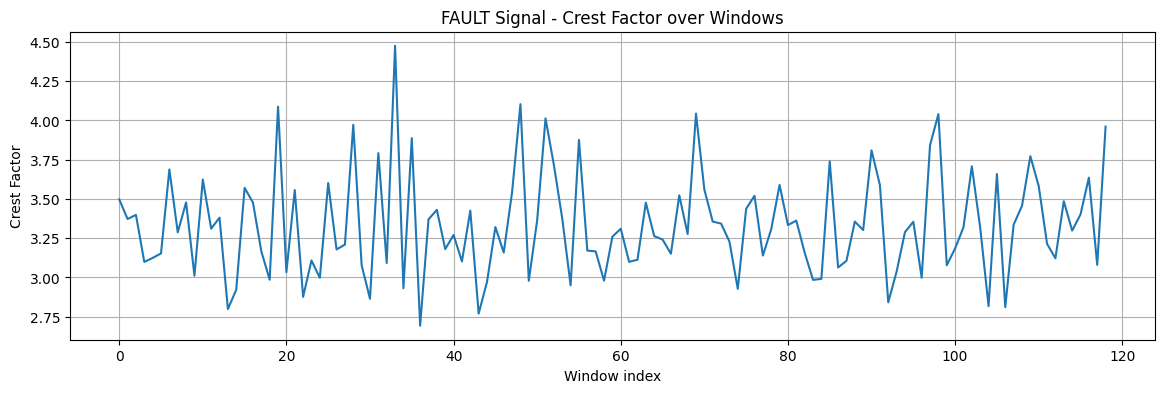

In [17]:
plt.figure(figsize=(14, 4))
plt.plot(df_fault_feats["rms"])
plt.title("FAULT Signal - RMS over Windows")
plt.xlabel("Window index")
plt.ylabel("RMS")
plt.grid(True)
plt.show()

plt.figure(figsize=(14, 4))
plt.plot(df_fault_feats["kurtosis"])
plt.title("FAULT Signal - Kurtosis over Windows")
plt.xlabel("Window index")
plt.ylabel("Kurtosis")
plt.grid(True)
plt.show()

plt.figure(figsize=(14, 4))
plt.plot(df_fault_feats["crest_factor"])
plt.title("FAULT Signal - Crest Factor over Windows")
plt.xlabel("Window index")
plt.ylabel("Crest Factor")
plt.grid(True)
plt.show()


In [18]:
def load_data(root_dir, target_pattern, label):
    all_features = []

    search_path = os.path.join(root_dir, "**", "*.mat")
    files = glob.glob(search_path, recursive=True)

    target_files = [f for f in files if target_pattern in f]

    print(f"Found {len(target_files)} files for '{target_pattern}'")

    for file_path in target_files:
        try:
            mat_data = scipy.io.loadmat(file_path)

            # find DE_time key
            de_key = None
            for k in mat_data.keys():
                if k.endswith("DE_time"):
                    de_key = k
                    break

            if de_key:
                signal = mat_data[de_key].flatten()
                feats = extract_features(signal)
                all_features.append(feats)

        except Exception as e:
            print("Error:", e)

    if not all_features:
        return np.array([]), np.array([])

    X = np.vstack(all_features)
    y = np.full(X.shape[0], label)

    return X, y


In [19]:
X_normal, y_normal = load_data(dataset_path, "Normal", label=1)
X_fault, y_fault = load_data(dataset_path, "Fault", label=-1)

print("Normal shape:", X_normal.shape)
print("Fault shape:", X_fault.shape)


Found 4 files for 'Normal'
Found 157 files for 'Fault'
Normal shape: (1656, 8)
Fault shape: (33414, 8)


In [20]:
X_train, X_test_normal, _, y_test_normal = train_test_split(
    X_normal, y_normal, test_size=0.2, random_state=42
)

X_test = np.vstack([X_test_normal, X_fault])
y_test = np.concatenate([y_test_normal, y_fault])

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [21]:
model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
model.fit(X_train_scaled)


OneClassSVM(nu=0.05)

In [22]:
y_pred = model.predict(X_test_scaled)

print(classification_report(
    y_test, y_pred, target_names=["Anomaly", "Normal"]
))


              precision    recall  f1-score   support

     Anomaly       1.00      1.00      1.00     33414
      Normal       0.95      0.92      0.93       332

    accuracy                           1.00     33746
   macro avg       0.97      0.96      0.97     33746
weighted avg       1.00      1.00      1.00     33746



In [23]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

fault_mask = (y_test == -1)
fault_detection = np.mean(y_pred[fault_mask] == -1)

normal_mask = (y_test == 1)
false_alarm_rate = np.mean(y_pred[normal_mask] == -1)

print(f"\nFault Detection Rate: {fault_detection:.2%}")
print(f"False Alarm Rate: {false_alarm_rate:.2%}")


Confusion Matrix:
[[33398    16]
 [   28   304]]

Fault Detection Rate: 99.95%
False Alarm Rate: 8.43%
